# Задание II. МНК и потеря точности

В этом опыте проверим, как округление при вычислении $A^\top A$ влияет на решение задачи МНК.
Возьмите матрицу Лёйхли:

$$
A_\varepsilon=\begin{bmatrix}\mathbf{1}_m^\top\\ \varepsilon I_m\end{bmatrix},\qquad
A_\varepsilon^\top A_\varepsilon=\mathbf{1}_m\mathbf{1}_m^\top+\varepsilon^2 I_m,\qquad
m=8,\quad \varepsilon>0
$$

Здесь $\mathbf{1}_m$ $\text{---}$ вектор из единиц. При любом $\varepsilon>0$ столбцы $A_\varepsilon$ линейно независимы. Задайте точное решение и правую часть:

$$
x_j^*=1+\frac{j}{m},\qquad j=1,\ldots,m,\qquad b=A_\varepsilon x^*
$$

Используйте $\varepsilon=2^{-k}$ при $k=4,8,12,16,20,24,26,27,30$. Все элементы $A_\varepsilon$, $b$, $x^*$ точно представимы в `float64`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import NDArray

for _cand in (Path.cwd() / "src", Path.cwd().parent / "src", Path("src")):
    if _cand.is_dir():
        sys.path.insert(0, str(_cand.resolve()))
        break

from lstsq_accuracy import M, POWERS_FLOAT32, POWERS_FLOAT64
from mnk.lstsq import lstsq

METHODS = ("qr", "normal_ldlt", "normal_lup")
x_star64 = 1 + np.arange(1, M + 1, dtype=np.float64) / M

In [2]:
def text_table(headers, rows):
    columns = [[str(h)] + [str(row[j]) for row in rows] for j, h in enumerate(headers)]
    widths = [max(len(cell) for cell in column) for column in columns]

    lines = []
    for i in range(len(rows) + 1):
        values = [
            column[i].ljust(w) if j == 0 else column[i].rjust(w)
            for j, (column, w) in enumerate(zip(columns, widths))
        ]
        lines.append("  ".join(values))
    lines.insert(1, "  ".join("-" * w for w in widths))
    return "\n".join(lines)

## 1. Обусловленность.

Используя равенство

$$
\|A_\varepsilon z\|_2^2=(\mathbf{1}_m^\top z)^2+\varepsilon^2\|z\|_2^2
$$

покажите, что

$$
\kappa_2(A_\varepsilon)=\frac{\sqrt{m+\varepsilon^2}}{\varepsilon}
$$

Рассмотрите векторы вдоль $\mathbf{1}_m$ и ортогонально ему. Какие строки $A_\varepsilon$ позволяют различить два вектора с одинаковой суммой компонент? Как уменьшение $\varepsilon$ влияет на это различие?

**Решение.** Разложим $z=\alpha e+w$, где $e=\mathbf1_m/\sqrt m$ и $e^\top w=0$. Тогда

$$
\|A_\varepsilon z\|_2^2=(m+\varepsilon^2)\alpha^2+\varepsilon^2\|w\|_2^2,
$$

поэтому вдоль $e$ длина умножается на $\sqrt{m+\varepsilon^2}$, в ортогональных направлениях $\text{---}$ на $\varepsilon$, значит,

$$
\kappa_2(A_\varepsilon)=\frac{\sqrt{m+\varepsilon^2}}{\varepsilon}.
$$

Векторы с одинаковой суммой компонент различаются по нижним восьми строкам, потому что первая строка даёт для них одинаковый результат:

$$
A_\varepsilon(x-y)=\begin{bmatrix}0\\\varepsilon(x-y)\end{bmatrix}.
$$

При уменьшении $\varepsilon$ различие уменьшается пропорционально $\varepsilon$.


## 2. Сравнение методов.

Решите задачу МНК методами `qr`, `normal_ldlt` и `normal_lup`. Для каждого $\varepsilon$ вычислите относительную ошибку решения и относительную невязку:

$$
\frac{\|\widetilde{x}-x^*\|_2}{\|x^*\|_2},\qquad
\frac{\|b-A_\varepsilon\widetilde{x}\|_2}{\|b\|_2}
$$

Также вычислите величину

$$
\omega=\frac{\|A_\varepsilon^\top(b-A_\varepsilon\widetilde{x})\|_2}
{\|A_\varepsilon\|_F\bigl(\|A_\varepsilon\|_F\|\widetilde{x}\|_2+\|b\|_2\bigr)}
$$

Она показывает, насколько точно найденное решение удовлетворяет нормальным уравнениям. Все показатели считайте по исходным $A_\varepsilon$, $b$. Для $\omega$ сначала вычислите $r=b-A_\varepsilon\widetilde{x}$, затем $A_\varepsilon^\top r$, не используя уже округлённые $A_\varepsilon^\top A_\varepsilon$ и $A_\varepsilon^\top b$. Если метод встретил нулевой ведущий элемент или вернул NaN либо бесконечность, отметьте отказ. Малый ненулевой ведущий элемент не зануляйте и не заменяйте другим числом. Регуляризацию не добавляйте.

In [3]:
def lauchli_system(k: int, dtype: type[np.floating]) -> tuple[NDArray, NDArray]:
    eps = dtype(2.0**-k)
    x_star = np.ones(M, dtype=dtype) + np.arange(1, M + 1, dtype=dtype) / dtype(M)
    A = np.vstack((np.ones((1, M), dtype=dtype), eps * np.eye(M, dtype=dtype)))
    b = A @ x_star
    return A, b


def solution_metrics(
    A: NDArray, b: NDArray, x: NDArray
) -> tuple[np.floating, np.floating, np.floating]:
    A64, b64 = A.astype(np.float64), b.astype(np.float64)
    x64 = x.astype(np.float64)
    r = b64 - A64 @ x64
    A_norm = np.linalg.norm(A64, ord="fro")
    error = np.linalg.norm(x64 - x_star64) / np.linalg.norm(x_star64)
    residual = np.linalg.norm(r) / np.linalg.norm(b64)
    omega = np.linalg.norm(A64.T @ r) / (
        A_norm * (A_norm * np.linalg.norm(x64) + np.linalg.norm(b64))
    )
    return error, residual, omega


def compare_methods(
    powers: list[int], dtype: type[np.floating]
) -> tuple[NDArray, NDArray, NDArray]:
    errors = np.full((len(powers), len(METHODS)), np.nan)
    residuals = np.full_like(errors, np.nan)
    omegas = np.full_like(errors, np.nan)

    for i, k in enumerate(powers):
        A, b = lauchli_system(k, dtype)
        for j, method in enumerate(METHODS):
            try:
                x = lstsq(A, b, method=method)
            except ArithmeticError:
                continue
            if not np.all(np.isfinite(x)):
                continue
            assert x.dtype == np.dtype(dtype)
            errors[i, j], residuals[i, j], omegas[i, j] = solution_metrics(A, b, x)

    return errors, residuals, omegas

In [4]:
def print_results(
    powers: list[int], errors: NDArray, residuals: NDArray, omegas: NDArray
) -> None:
    rows = []
    for i, k in enumerate(powers):
        eps = 2.0**-k
        kappa = np.sqrt(M + eps**2) / eps
        for j, method in enumerate(METHODS):
            values = [
                f"{value:.3e}" if np.isfinite(value) else "отказ"
                for value in (errors[i, j], residuals[i, j], omegas[i, j])
            ]
            rows.append([str(k), f"{eps:.3e}", f"{kappa:.3e}", method, *values])
    print(
        text_table(["k", "eps", "kappa_2", "метод", "error", "residual", "omega"], rows)
    )

In [5]:
errors64, residuals64, omegas64 = compare_methods(POWERS_FLOAT64, np.float64)
print_results(POWERS_FLOAT64, errors64, residuals64, omegas64)

k         eps    kappa_2        метод      error   residual      omega
--  ---------  ---------  -----------  ---------  ---------  ---------
4   6.250e-02  4.527e+01           qr  5.481e-16  1.231e-17  1.345e-19
4   6.250e-02  4.527e+01  normal_ldlt  1.339e-13  3.008e-15  3.287e-17
4   6.250e-02  4.527e+01   normal_lup  1.208e-13  2.712e-15  2.963e-17
8   3.906e-03  7.241e+02           qr  4.867e-16  1.421e-16  7.047e-17
8   3.906e-03  7.241e+02  normal_ldlt  2.221e-11  3.119e-14  7.363e-17
8   3.906e-03  7.241e+02   normal_lup  1.743e-11  2.448e-14  1.676e-17
12  2.441e-04  1.159e+04           qr  6.367e-16  1.421e-16  7.047e-17
12  2.441e-04  1.159e+04  normal_ldlt  5.375e-09  4.716e-13  2.019e-17
12  2.441e-04  1.159e+04   normal_lup  5.899e-09  5.177e-13  7.387e-17
16  1.526e-05  1.854e+05           qr  3.006e-16  1.649e-21  4.411e-27
16  1.526e-05  1.854e+05  normal_ldlt  1.042e-06  5.715e-12  7.211e-17
16  1.526e-05  1.854e+05   normal_lup  7.526e-07  4.128e-12  1.104e-17
20  9.

У QR ошибка на всей сетке имеет порядок $10^{-16}$.
У нормальных уравнений при $k=24$ ошибки LDLT и LUP достигают $0.190$ и $0.170$, при $k=26$ $\text{---}$ $1.23$ и $2.33$ при невязках порядка $10^{-8}$ и $\omega$ порядка $10^{-17}$.
При $k=27$ и $k=30$ оба нормальных метода отказывают из-за нулевого ведущего элемента.


## 3. Потеря информации.

Для каждого $\varepsilon$ вычислите $(1+\varepsilon^2)-1$, сначала сохранив сумму в переменной рабочего типа, затем выполнив вычитание. Единицу и $\varepsilon$ также задавайте в этом типе. Не упрощайте выражение до $\varepsilon^2$, иначе исчезнет исследуемое округление. При каком $k$ результат впервые становится нулём? Что при этом происходит с вычисленной матрицей $A_\varepsilon^\top A_\varepsilon$? Вычислите также разности $(A_\varepsilon^\top b)_j-b_1$ и сравните их с точными значениями $\varepsilon^2 x_j^*$. Сами компоненты $b_1+\varepsilon^2 x_j^*$ могут быть непредставимы в рабочем типе, а при вычитании близкого к ним числа $b_1$ новой ошибки округления не возникает. При каком $k$ разности впервые отличаются от точных значений и при каком обращаются в ноль? Объясните, почему переход от LDLT к LUP не возвращает информацию, потерянную при составлении нормальных уравнений. Могут ли относительная невязка и $\omega$ быть малыми при большой ошибке решения?


In [6]:
def rounding_experiment(
    powers: list[int], dtype: type[np.floating]
) -> tuple[NDArray, NDArray]:
    one = dtype(1)
    deltas = np.empty(len(powers), dtype=dtype)
    rhs_diffs = np.empty((len(powers), M), dtype=dtype)

    for i, k in enumerate(powers):
        eps = dtype(2.0**-k)
        eps_sq = eps * eps
        rounded_sum = one + eps_sq
        deltas[i] = rounded_sum - one
        A, b = lauchli_system(k, dtype)
        rhs = A.T @ b
        rhs_diffs[i] = rhs - b[0]

    return deltas, rhs_diffs


def print_rounding(powers: list[int], deltas: NDArray, rhs_diffs: NDArray) -> None:
    rows = []
    for i, k in enumerate(powers):
        eps_sq = (2.0**-k) ** 2
        exact = eps_sq * x_star64
        observed = rhs_diffs[i].astype(np.float64)
        rel_error = np.max(np.abs(observed - exact) / exact)
        changed = np.count_nonzero(observed != exact)
        zeros = np.count_nonzero(observed == 0)
        rows.append(
            [
                str(k),
                f"{eps_sq:.3e}",
                f"{deltas[i]:.3e}",
                f"{rel_error:.3e}",
                f"{changed}/{M}",
                f"{zeros}/{M}",
            ]
        )
    print(
        text_table(
            [
                "k",
                "eps^2",
                "(1+eps^2)-1",
                "max отн. ошибка RHS",
                "искажено",
                "нулей",
            ],
            rows,
        )
    )

In [7]:
deltas64, rhs_diffs64 = rounding_experiment(POWERS_FLOAT64, np.float64)
print_rounding(POWERS_FLOAT64, deltas64, rhs_diffs64)

k       eps^2  (1+eps^2)-1  max отн. ошибка RHS  искажено  нулей
--  ---------  -----------  -------------------  --------  -----
4   3.906e-03    3.906e-03            0.000e+00       0/8    0/8
8   1.526e-05    1.526e-05            0.000e+00       0/8    0/8
12  5.960e-08    5.960e-08            0.000e+00       0/8    0/8
16  2.328e-10    2.328e-10            0.000e+00       0/8    0/8
20  9.095e-13    9.095e-13            0.000e+00       0/8    0/8
24  3.553e-15    3.553e-15            2.000e-01       6/8    0/8
26  2.220e-16    2.220e-16            1.000e+00       8/8    8/8
27  5.551e-17    0.000e+00            1.000e+00       8/8    8/8
30  8.674e-19    0.000e+00            1.000e+00       8/8    8/8


In [8]:
for k in (24, 26):
    i = POWERS_FLOAT64.index(k)
    exact = (2.0**-k) ** 2 * x_star64
    print(f"{k=}")
    print(
        text_table(
            ["j", "точное eps^2 x*_j", "(A.T b)_j - b_1"],
            [
                [str(j + 1), f"{exact[j]:.6e}", f"{rhs_diffs64[i, j]:.6e}"]
                for j in range(M)
            ],
        )
    )
    print()

k=24
j  точное eps^2 x*_j  (A.T b)_j - b_1
-  -----------------  ---------------
1       3.996803e-15     3.552714e-15
2       4.440892e-15     3.552714e-15
3       4.884981e-15     5.329071e-15
4       5.329071e-15     5.329071e-15
5       5.773160e-15     5.329071e-15
6       6.217249e-15     7.105427e-15
7       6.661338e-15     7.105427e-15
8       7.105427e-15     7.105427e-15

k=26
j  точное eps^2 x*_j  (A.T b)_j - b_1
-  -----------------  ---------------
1       2.498002e-16     0.000000e+00
2       2.775558e-16     0.000000e+00
3       3.053113e-16     0.000000e+00
4       3.330669e-16     0.000000e+00
5       3.608225e-16     0.000000e+00
6       3.885781e-16     0.000000e+00
7       4.163336e-16     0.000000e+00
8       4.440892e-16     0.000000e+00



In [9]:
A27, b27 = lauchli_system(27, np.float64)
G27 = A27.T @ A27
print(G27)
print("Все элементы равны 1:", np.all(G27 == 1))

[[1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1. 1.]]
Все элементы равны 1: True


В `float64` результат $(1+\varepsilon^2)-1$ впервые равен нулю при $k=27$, потому что $\varepsilon^2=2^{-54}$ теряется при прибавлении к 1.
Матрица Грама становится матрицей из единиц ранга 1, поэтому оба нормальных метода встречают нулевой ведущий элемент.

Разности $(A_\varepsilon^\top b)_j-b_1$ впервые искажаются при $k=24$ и все обнуляются при $k=26$.
Это происходит раньше, потому что в сумме $b_1+\varepsilon^2x_j^*$ число $b_1=12.5$ имеет шаг $2^{-49}$, тогда как возле 1 шаг равен $2^{-52}$.
Округление происходит при сложении, последующее вычитание $b_1$ здесь выполняется точно.

Переход от LDLT к LUP не возвращает потерянную информацию, потому что оба метода получают уже округлённые $A_\varepsilon^\top A_\varepsilon$ и $A_\varepsilon^\top b$.

Да, невязка и $\omega$ могут быть малыми при большой ошибке решения, потому что для составляющей ошибки $e$, ортогональной $\mathbf1_m$,

$$
\|A_\varepsilon e\|_2=\varepsilon\|e\|_2,\qquad
A_\varepsilon^\top A_\varepsilon e=\varepsilon^2e.
$$

Значит, такая ошибка слабо меняет $A_\varepsilon\widetilde x$ и ещё слабее влияет на $A_\varepsilon^\top r$.


## 4. Влияние точности.

Повторите опыт в `float32` для $k=2,4,6,8,10,11,12,13,16$. В `float32` выполняйте и построение $A_\varepsilon^\top A_\varepsilon$, $A_\varepsilon^\top b$, и само решение, и опыт с $(1+\varepsilon^2)-1$. Одного преобразования готового ответа недостаточно. Ошибки, невязки и $\omega$ вычисляйте отдельно в `float64`. Сравните $\varepsilon^2$ с единицей округления $u$ в момент, когда $(1+\varepsilon^2)-1$ становится нулём. Для обеих точностей постройте графики относительной ошибки решения в зависимости от $\kappa_2(A_\varepsilon)$. Отказы методов отметьте отдельно. Сравните ошибки с ориентирами $u\kappa_2(A_\varepsilon)$ для QR и $u\kappa_2(A_\varepsilon)^2$ для нормальных уравнений на участке, где ошибки малы. Ориентиры задают оценку сверху по порядку величины, поэтому фактическая ошибка может оказаться заметно меньше. Если так произошло, объясните, почему это не противоречит оценке.

**Nota Bene.**

Для проверки переведите данные и ответ в `float64` до арифметических операций:

```python
A64, b64 = A.astype(np.float64), b.astype(np.float64)
x64 = x.astype(np.float64)
r = b64 - A64 @ x64
error = np.linalg.norm(x64 - x_star64) / np.linalg.norm(x_star64)
```

Здесь `x_star64` $\text{---}$ заданный $x^*$, вычисленный по формуле в `float64`. Перевод ответа в `float64` позволяет точнее измерить накопленную ошибку. В этом опыте данные точно представимы и в `float32`, поэтому перевод $A$, $b$ в него не меняет их значений. Единица округления для сравнений равна `np.finfo(dtype).eps / 2`.


In [10]:
A32, b32 = lauchli_system(2, np.float32)
x32 = lstsq(A32, b32, method="qr")
print("A:", A32.dtype, "b:", b32.dtype)
print("A.T @ A:", (A32.T @ A32).dtype, "A.T @ b:", (A32.T @ b32).dtype)
print("Решение QR:", x32.dtype)

errors32, residuals32, omegas32 = compare_methods(POWERS_FLOAT32, np.float32)
print_results(POWERS_FLOAT32, errors32, residuals32, omegas32)

A: float32 b: float32
A.T @ A: float32 A.T @ b: float32
Решение QR: float32
k         eps    kappa_2        метод      error   residual      omega
--  ---------  ---------  -----------  ---------  ---------  ---------
2   2.500e-01  1.136e+01           qr  1.760e-07  5.913e-08  2.727e-08
2   2.500e-01  1.136e+01  normal_ldlt  2.135e-06  1.994e-07  2.842e-08
2   2.500e-01  1.136e+01   normal_lup  1.921e-06  1.761e-07  1.955e-08
4   6.250e-02  4.527e+01           qr  3.799e-07  1.279e-08  4.718e-09
4   6.250e-02  4.527e+01  normal_ldlt  4.263e-05  9.581e-07  2.157e-08
4   6.250e-02  4.527e+01   normal_lup  4.214e-05  9.475e-07  2.575e-08
6   1.562e-02  1.810e+02           qr  2.820e-07  2.865e-08  1.418e-08
6   1.562e-02  1.810e+02  normal_ldlt  5.376e-04  3.019e-06  1.642e-08
6   1.562e-02  1.810e+02   normal_lup  5.788e-04  3.251e-06  1.008e-08
8   3.906e-03  7.241e+02           qr  1.094e-07  9.538e-09  4.729e-09
8   3.906e-03  7.241e+02  normal_ldlt  9.572e-03  1.344e-05  1.319e-08
8

In [11]:
deltas32, rhs_diffs32 = rounding_experiment(POWERS_FLOAT32, np.float32)
print_rounding(POWERS_FLOAT32, deltas32, rhs_diffs32)

k       eps^2  (1+eps^2)-1  max отн. ошибка RHS  искажено  нулей
--  ---------  -----------  -------------------  --------  -----
2   6.250e-02    6.250e-02            0.000e+00       0/8    0/8
4   3.906e-03    3.906e-03            0.000e+00       0/8    0/8
6   2.441e-04    2.441e-04            0.000e+00       0/8    0/8
8   1.526e-05    1.526e-05            0.000e+00       0/8    0/8
10  9.537e-07    9.537e-07            3.333e-01       7/8    0/8
11  2.384e-07    2.384e-07            1.000e+00       8/8    8/8
12  5.960e-08    0.000e+00            1.000e+00       8/8    8/8
13  1.490e-08    0.000e+00            1.000e+00       8/8    8/8
16  2.328e-10    0.000e+00            1.000e+00       8/8    8/8


In [12]:
for k in (10, 11):
    i = POWERS_FLOAT32.index(k)
    exact = (2.0**-k) ** 2 * x_star64
    print(f"{k=}")
    print(
        text_table(
            ["j", "точное eps^2 x*_j", "(A.T b)_j - b_1"],
            [
                [str(j + 1), f"{exact[j]:.6e}", f"{rhs_diffs32[i, j]:.6e}"]
                for j in range(M)
            ],
        )
    )
    print()

k=10
j  точное eps^2 x*_j  (A.T b)_j - b_1
-  -----------------  ---------------
1       1.072884e-06     9.536743e-07
2       1.192093e-06     9.536743e-07
3       1.311302e-06     9.536743e-07
4       1.430511e-06     1.907349e-06
5       1.549721e-06     1.907349e-06
6       1.668930e-06     1.907349e-06
7       1.788139e-06     1.907349e-06
8       1.907349e-06     1.907349e-06

k=11
j  точное eps^2 x*_j  (A.T b)_j - b_1
-  -----------------  ---------------
1       2.682209e-07     0.000000e+00
2       2.980232e-07     0.000000e+00
3       3.278255e-07     0.000000e+00
4       3.576279e-07     0.000000e+00
5       3.874302e-07     0.000000e+00
6       4.172325e-07     0.000000e+00
7       4.470348e-07     0.000000e+00
8       4.768372e-07     0.000000e+00



In [13]:
rows = []
for dtype, powers, deltas in (
    (np.float64, POWERS_FLOAT64, deltas64),
    (np.float32, POWERS_FLOAT32, deltas32),
):
    first_zero = powers[int(np.flatnonzero(deltas == 0)[0])]
    u = np.finfo(dtype).eps / 2
    eps_sq = (2.0**-first_zero) ** 2
    rows.append(
        [
            dtype.__name__,
            str(first_zero),
            f"{eps_sq:.6e}",
            f"{u:.6e}",
            f"{eps_sq / u:.2f}",
        ]
    )
print(text_table(["тип", "первый k с нулём", "eps^2", "u", "eps^2/u"], rows))

A12, b12 = lauchli_system(12, np.float32)
print("Матрица Грама float32 при k=12 состоит из единиц:", np.all(A12.T @ A12 == 1))

тип      первый k с нулём         eps^2             u  eps^2/u
-------  ----------------  ------------  ------------  -------
float64                27  5.551115e-17  1.110223e-16     0.50
float32                12  5.960464e-08  5.960464e-08     1.00
Матрица Грама float32 при k=12 состоит из единиц: True


В `float32` ошибка QR остаётся порядка $10^{-7}$, у нормальных методов при $k=11$ она достигает $0.97$ при невязках около $1.7\cdot10^{-4}$ и $\omega$ порядка $10^{-8}$.
Первые значения $k$ на заданных сетках:

| Что произошло | `float64` | `float32` |
|:-|:-:|:-:|
| Разности $(A^\top b)_j-b_1$ отличаются от точных | 24 | 10 |
| Все разности $(A^\top b)_j-b_1$ равны нулю | 26 | 11 |
| $(1+\varepsilon^2)-1=0$ | 27 | 12 |

В `float32` диагональная добавка впервые исчезает при $\varepsilon^2=2^{-24}=u$, потому что сумма $1+\varepsilon^2$ лежит посередине между соседними числами и округление к ближайшему чётному даёт 1.
В `float64` в первой такой точке на сетке $\varepsilon^2=2^{-54}=u/2$.
Поэтому в `float32` нормальные методы отказывают уже при $k=12,13,16$.


In [14]:
def plot_errors(powers: list[int], errors: NDArray, dtype: type[np.floating]) -> None:
    eps = 2.0 ** -np.array(powers, dtype=np.float64)
    kappas = np.sqrt(M + eps**2) / eps
    u = np.finfo(dtype).eps / 2
    colors = ("C0", "C1", "C2")
    fig, axes = plt.subplots(
        2, 1, figsize=(8, 6), sharex=True, gridspec_kw={"height_ratios": [4, 1]}
    )

    for j, method in enumerate(METHODS):
        axes[0].loglog(kappas, errors[:, j], "o-", color=colors[j], label=method)

    small = u * kappas**2 <= 1
    axes[0].loglog(kappas, u * kappas, "--", color="0.4", label=r"$u\kappa_2$")
    axes[0].loglog(
        kappas[small], u * kappas[small] ** 2, ":", color="0.2", label=r"$u\kappa_2^2$"
    )
    axes[0].set_title(dtype.__name__)
    axes[0].set_ylabel("Относительная ошибка решения")
    axes[0].set_ylim(np.finfo(dtype).eps / 10, 10)
    axes[0].grid(True, which="both", alpha=0.3)
    axes[0].legend()

    for j, method in enumerate(METHODS[1:], start=1):
        failed = ~np.isfinite(errors[:, j])
        axes[1].plot(
            kappas[failed],
            np.full(np.count_nonzero(failed), j - 1),
            "x",
            color=colors[j],
            markersize=8,
        )
    axes[1].set_yticks([0, 1], labels=list(METHODS[1:]))
    axes[1].set_ylim(-0.5, 1.5)
    axes[1].set_ylabel("Отказы")
    axes[1].set_xlabel(r"$\kappa_2(A_\varepsilon)$")
    axes[1].grid(True, which="both", alpha=0.3)

    plt.tight_layout()
    plt.show()

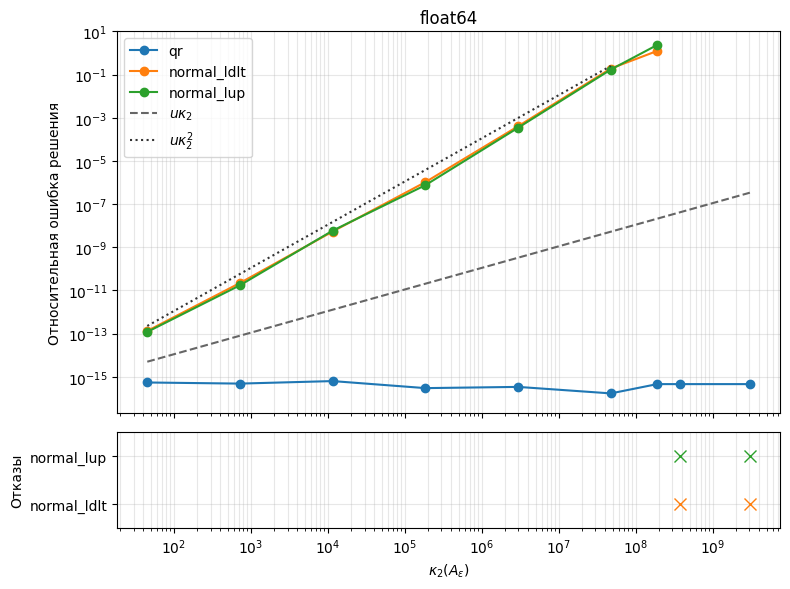

In [15]:
plot_errors(POWERS_FLOAT64, errors64, np.float64)

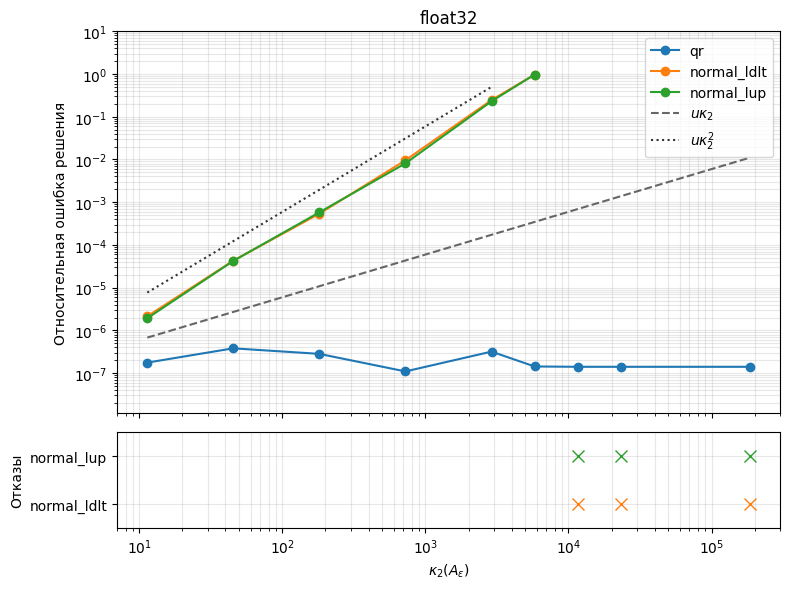

In [16]:
plot_errors(POWERS_FLOAT32, errors32, np.float32)

### Вывод

На участке малых ошибок нормальных методов их порядок согласуется с $u\kappa_2^2$:
при $k=20$ в `float64` ориентир равен $9.77\cdot10^{-4}$, ошибки LDLT и LUP $\text{---}$ $4.02\cdot10^{-4}$ и $3.44\cdot10^{-4}$.
При $k=8$ в `float32` ориентир равен $0.0313$, ошибки $\text{---}$ $0.00957$ и $0.00810$.

У QR при $k=30$ в `float64` ошибка около $4.6\cdot10^{-16}$ при $u\kappa_2\approx3.4\cdot10^{-7}$, при $k=8$ в `float32` $\text{---}$ $1.09\cdot10^{-7}$ при $u\kappa_2\approx4.32\cdot10^{-5}$.
Меньшая ошибка не противоречит оценке, потому что она задаёт верхний ориентир по порядку величины и не обязана достигаться в каждом опыте.
